#Project 12: Understanding Convolution and Pooling

1. Let’s import the libraries

We’ll use Python libraries like NumPy, Matplotlib and OpenCV to load images, apply filters and display the results.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

2. Let’s load a sample image

First, we’ll load an image using OpenCV and display it. We’ll use this image throughout the experiment to see how different filters and pooling operations change it.

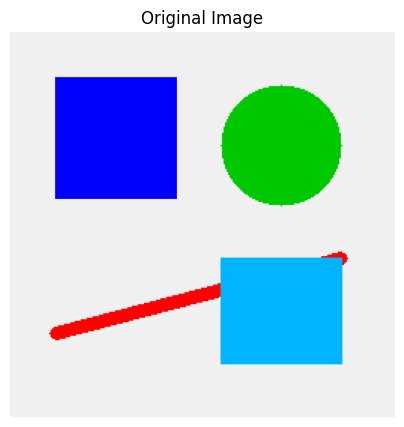

In [3]:
# Create a sample RGB image
image = np.zeros((256, 256, 3), dtype=np.uint8)

# Background
image[:] = (240, 240, 240)

# Draw shapes
cv2.rectangle(image, (30, 30), (110, 110), (255, 0, 0), -1)
cv2.circle(image, (180, 75), 40, (0, 200, 0), -1)
cv2.line(image, (30, 200), (220, 150), (0, 0, 255), 8)
cv2.rectangle(image, (140, 150), (220, 220), (255, 180, 0), -1)

# Convert BGR to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

3. Let’s convert the image to grayscale

We’ll convert the original image into grayscale so we can easily observe how the filters affect its pixel values and edges.

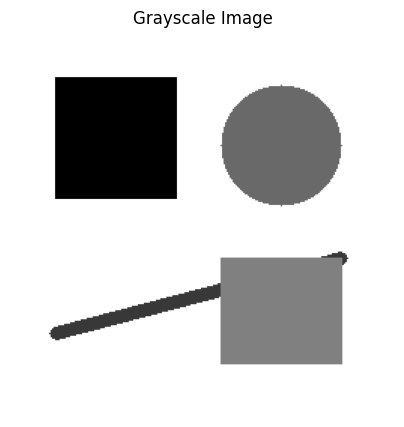

In [4]:
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(5, 5))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

4. Let’s try different convolution filters

Now we’ll apply different filters to the image and compare the results.
- Identity filter: Keeps the image almost unchanged.
- Edge detection filter: Highlights the edges and boundaries of objects.
- Sharpening filter: Makes the details and edges clearer.
- Blur filter: Smooths the image and reduces small details.

By looking at the output images, we can understand how each filter works.

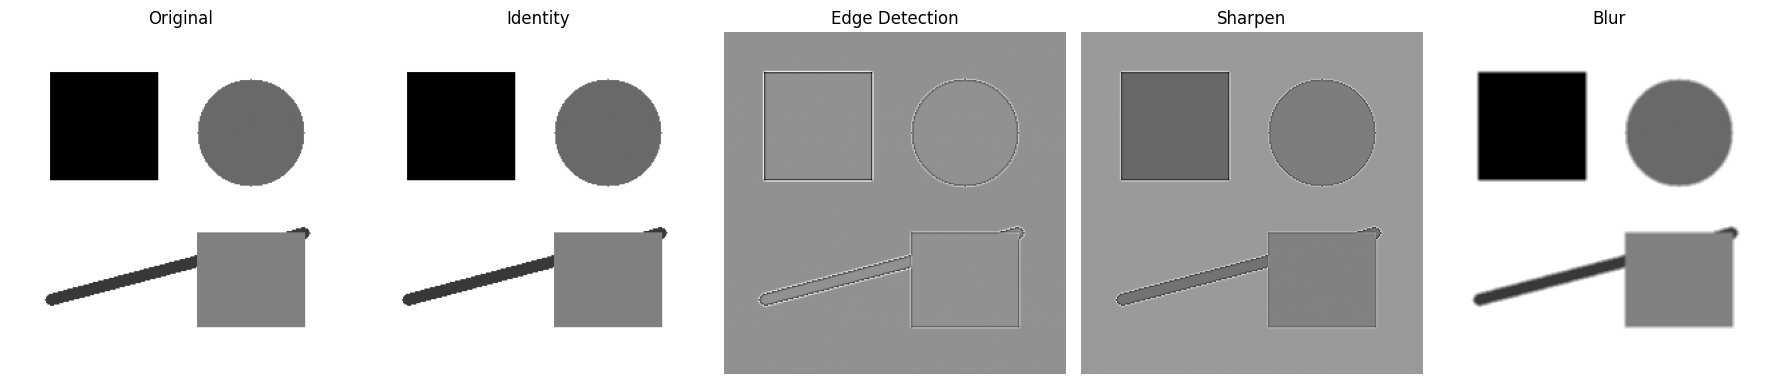

In [5]:
filters = {
    "Identity": np.array([
        [0, 0, 0],
        [0, 1, 0],
        [0, 0, 0]
    ], dtype=np.float32),

    "Edge Detection": np.array([
        [-1, -1, -1],
        [-1,  8, -1],
        [-1, -1, -1]
    ], dtype=np.float32),

    "Sharpen": np.array([
        [0, -1, 0],
        [-1, 5, -1],
        [0, -1, 0]
    ], dtype=np.float32),

    "Blur": np.ones((3, 3), dtype=np.float32) / 9
}

feature_maps = {}

for name, kernel in filters.items():
    feature_maps[name] = cv2.filter2D(
        gray, cv2.CV_32F, kernel
    )

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original")

for ax, (name, result) in zip(axes[1:], feature_maps.items()):
    ax.imshow(result, cmap="gray")
    ax.set_title(name)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

5. Let’s try max pooling and average pooling

Pooling helps reduce the size of an image while keeping important information.
- Max pooling: Keeps the maximum pixel value from each small region.
- Average pooling: Calculates the average pixel value of each small region.

We’ll compare both results to see how they affect the image.

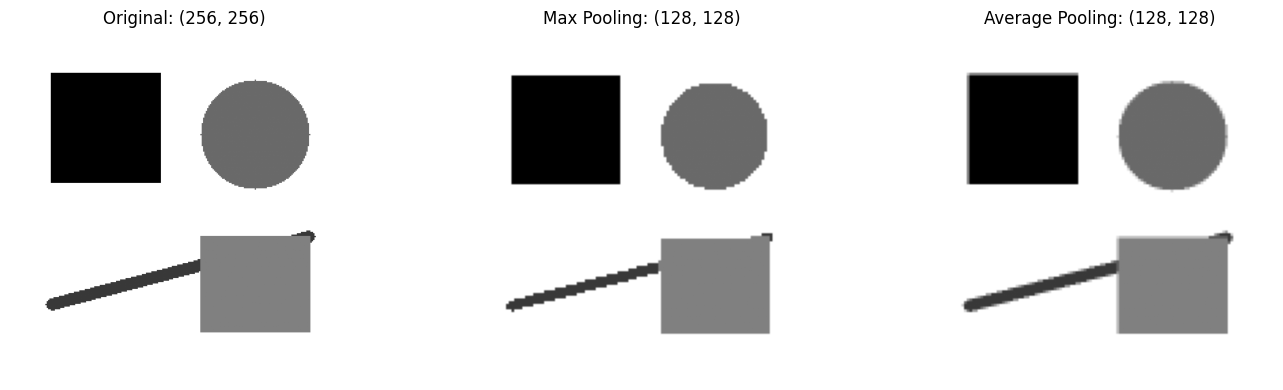

In [6]:

max_pool = cv2.dilate(
    gray, np.ones((2, 2), dtype=np.uint8)
)[::2, ::2]

average_pool = cv2.blur(
    gray.astype(np.float32), (2, 2)
)[::2, ::2]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title(f"Original: {gray.shape}")

axes[1].imshow(max_pool, cmap="gray")
axes[1].set_title(f"Max Pooling: {max_pool.shape}")

axes[2].imshow(average_pool, cmap="gray")
axes[2].set_title(f"Average Pooling: {average_pool.shape}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

6. Let’s compare the images

Here, we’ll display the original image alongside the filtered and pooled images. This will help us see which details are highlighted, smoothed or reduced by each operation.

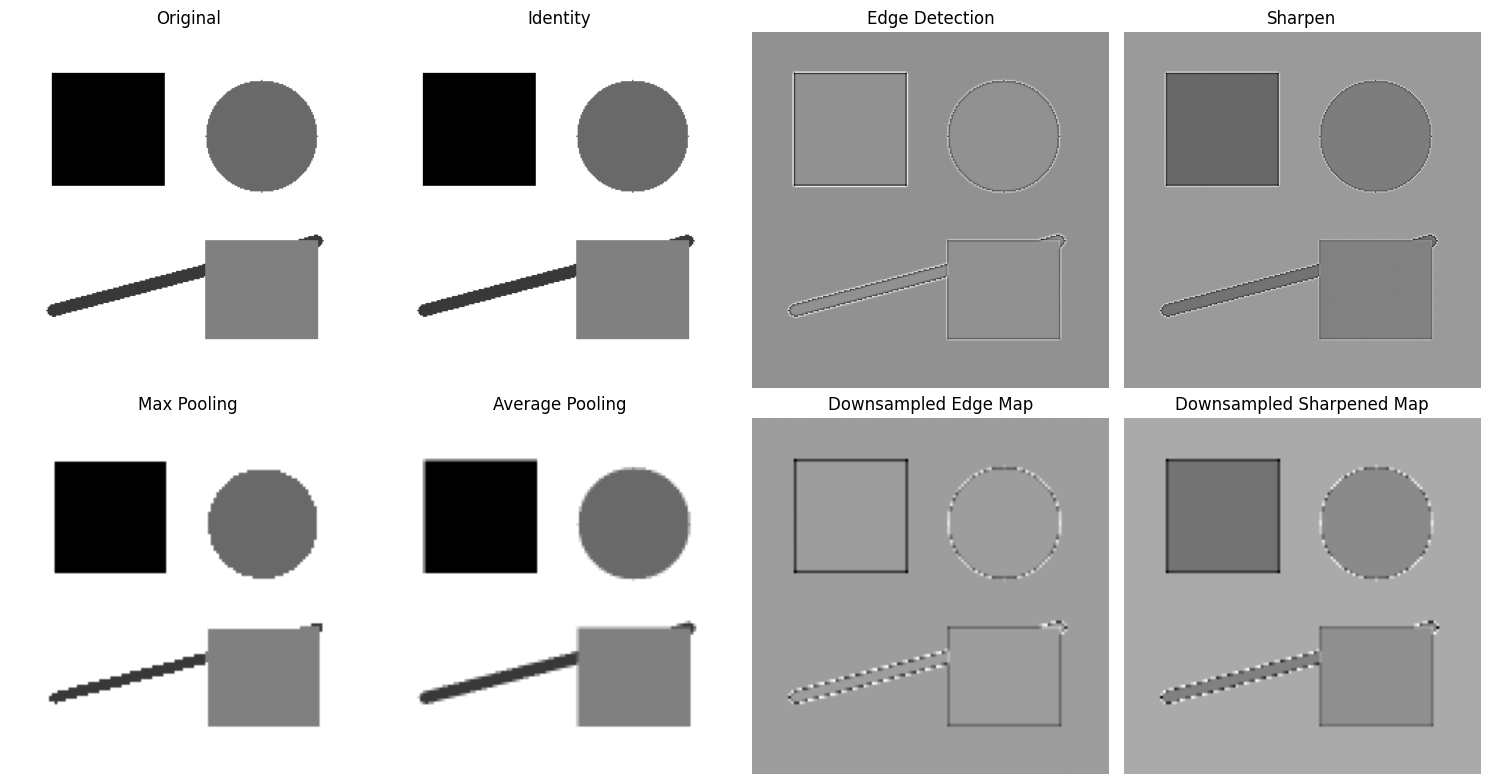

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

# Original and convolution outputs
axes[0, 0].imshow(gray, cmap="gray")
axes[0, 0].set_title("Original")

for ax, (name, result) in zip(axes[0, 1:], feature_maps.items()):
    ax.imshow(result, cmap="gray")
    ax.set_title(name)

# Pooling outputs and an edge map
axes[1, 0].imshow(max_pool, cmap="gray")
axes[1, 0].set_title("Max Pooling")

axes[1, 1].imshow(average_pool, cmap="gray")
axes[1, 1].set_title("Average Pooling")

axes[1, 2].imshow(feature_maps["Edge Detection"][::2, ::2], cmap="gray")
axes[1, 2].set_title("Downsampled Edge Map")

axes[1, 3].imshow(feature_maps["Sharpen"][::2, ::2], cmap="gray")
axes[1, 3].set_title("Downsampled Sharpened Map")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

7. Let’s check the image values

We’ll print the shape, minimum pixel value and maximum pixel value of the images. This helps us understand how the image data changes after applying different operations

In [8]:
comparison = {
    "Original": gray,
    "Identity": feature_maps["Identity"],
    "Edge Detection": feature_maps["Edge Detection"],
    "Sharpen": feature_maps["Sharpen"],
    "Blur": feature_maps["Blur"],
    "Max Pooling": max_pool,
    "Average Pooling": average_pool
}

for name, result in comparison.items():
    print(
        f"{name:18} | Shape: {str(result.shape):12} | "
        f"Min: {result.min():8.2f} | Max: {result.max():8.2f}"
    )

Original           | Shape: (256, 256)   | Min:    29.00 | Max:   240.00
Identity           | Shape: (256, 256)   | Min:    29.00 | Max:   240.00
Edge Detection     | Shape: (256, 256)   | Min: -1055.00 | Max:   807.00
Sharpen            | Shape: (256, 256)   | Min:  -416.00 | Max:   673.00
Blur               | Shape: (256, 256)   | Min:    29.00 | Max:   240.00
Max Pooling        | Shape: (128, 128)   | Min:    29.00 | Max:   240.00
Average Pooling    | Shape: (128, 128)   | Min:    29.00 | Max:   240.00


8. Conclusion

In this experiment, we used Python and OpenCV to understand how convolution and pooling work on images. We applied different filters, such as edge detection, sharpening and blur, and compared max pooling with average pooling.

We learned that convolution filters help identify useful features such as edges and details, while pooling reduces the size of feature maps. These operations are important parts of CNNs and are widely used in image classification and other computer vision tasks.

Result: We observed how different convolution filters and pooling operations change an image and learned how they help CNNs extract useful features.